# AFO — exploration

AFO (Aerial dataset of Floating Objects): 3,641 drone images, 39,991 hand-annotated objects, 6 classes.
Paper: Gąsienica-Józkowy, Knapik, Cyganek, *Integrated Computer-Aided Engineering* 28(3), 2021, [doi:10.3233/ICA-210649](https://doi.org/10.3233/ICA-210649).

This notebook draws 10 random images per split with boxes, and plots the class and object-size histograms.
The dataset downloads into `~/.cache/afo` (override with `AFO_ROOT`); nothing is written to the repository.

In [1]:
import math
import random
import warnings
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle

from afo.classes import display_name
from afo.dataset import SPLITS, AFODataset
from afo.download import ensure_dataset

SEED = 0
ensure_dataset()

with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    ds = {s: AFODataset(s, clip=True) for s in SPLITS}

CLASSES = ds['train'].class_names            # pisownia z .names — zrodlo prawdy
LABELS = [display_name(c) for c in CLASSES]  # pisownia poprawiona, tylko na wykresy

for s in SPLITS:
    print(f'{s:6s} {len(ds[s]):5d} images  {ds[s].num_objects():6d} objects')
print('classes:', ', '.join(LABELS))

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 14574 files:   0%|          | 0/14574 [00:00<?, ?it/s]

train   2787 images   26960 objects
val      339 images    5392 objects
test     514 images    7639 objects
classes: human, wind/sup-board, boat, buoy, sailboat, kayak


## 1. Random samples with boxes — 10 per split

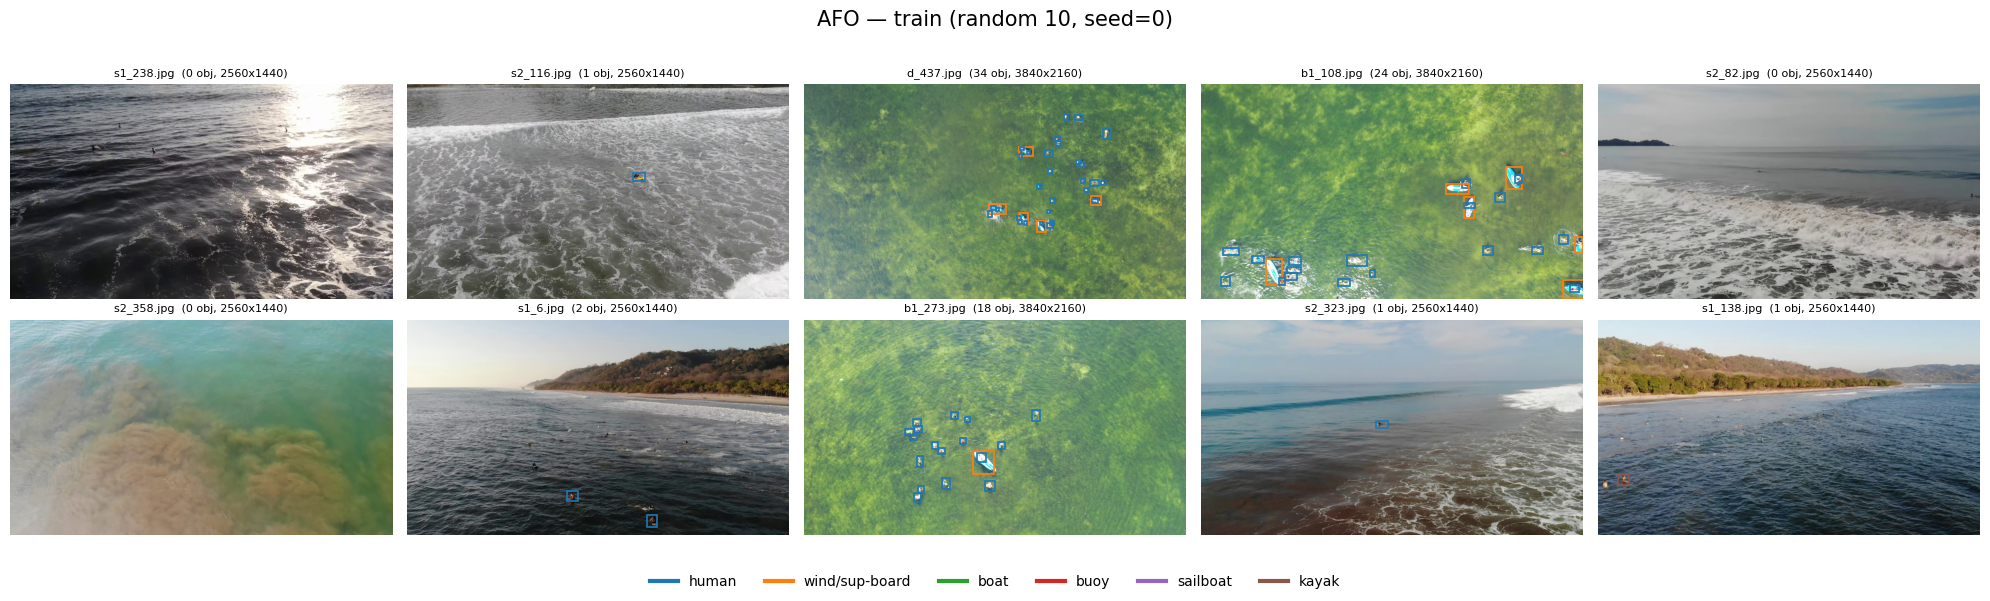

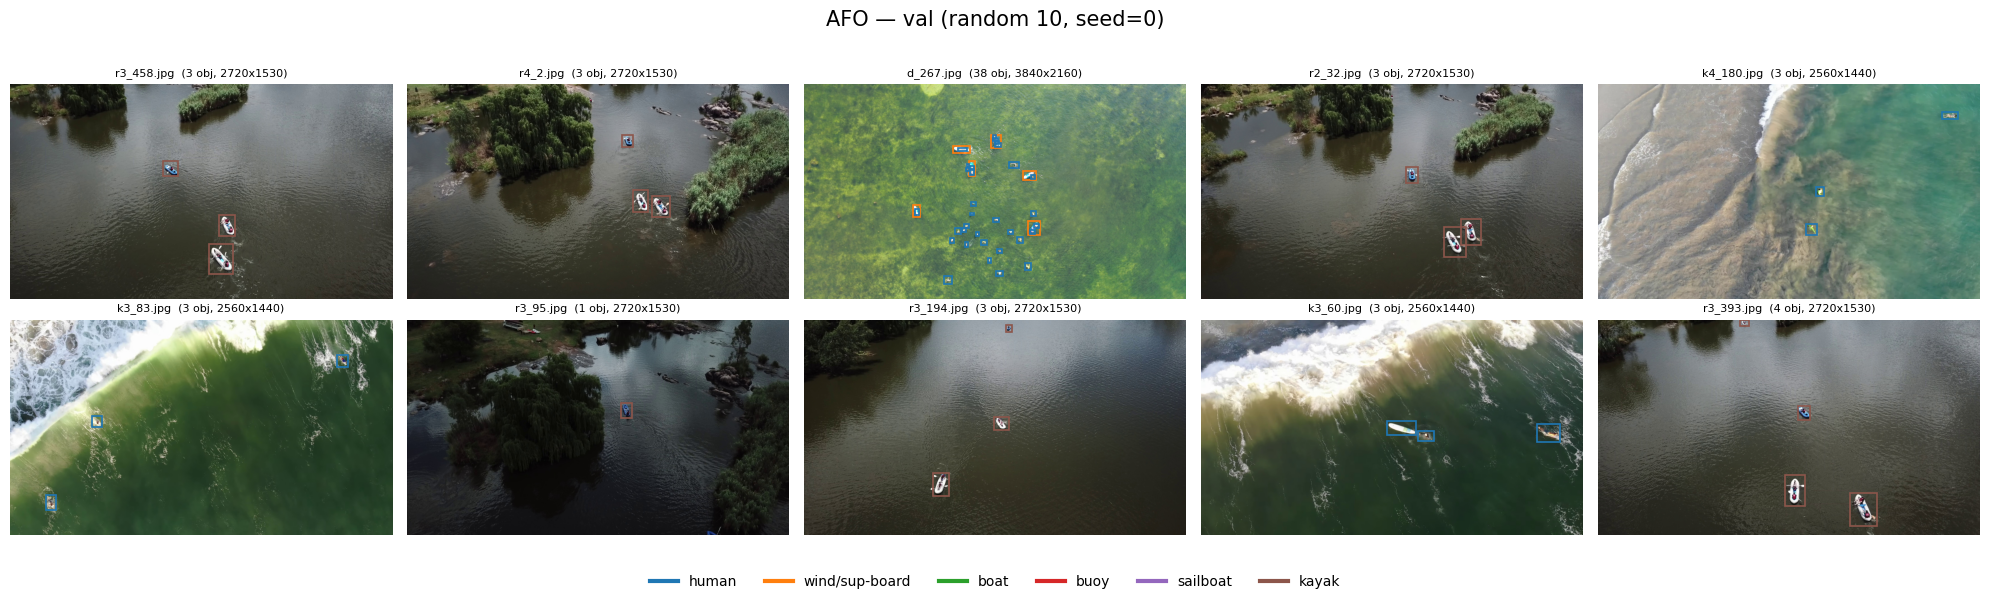

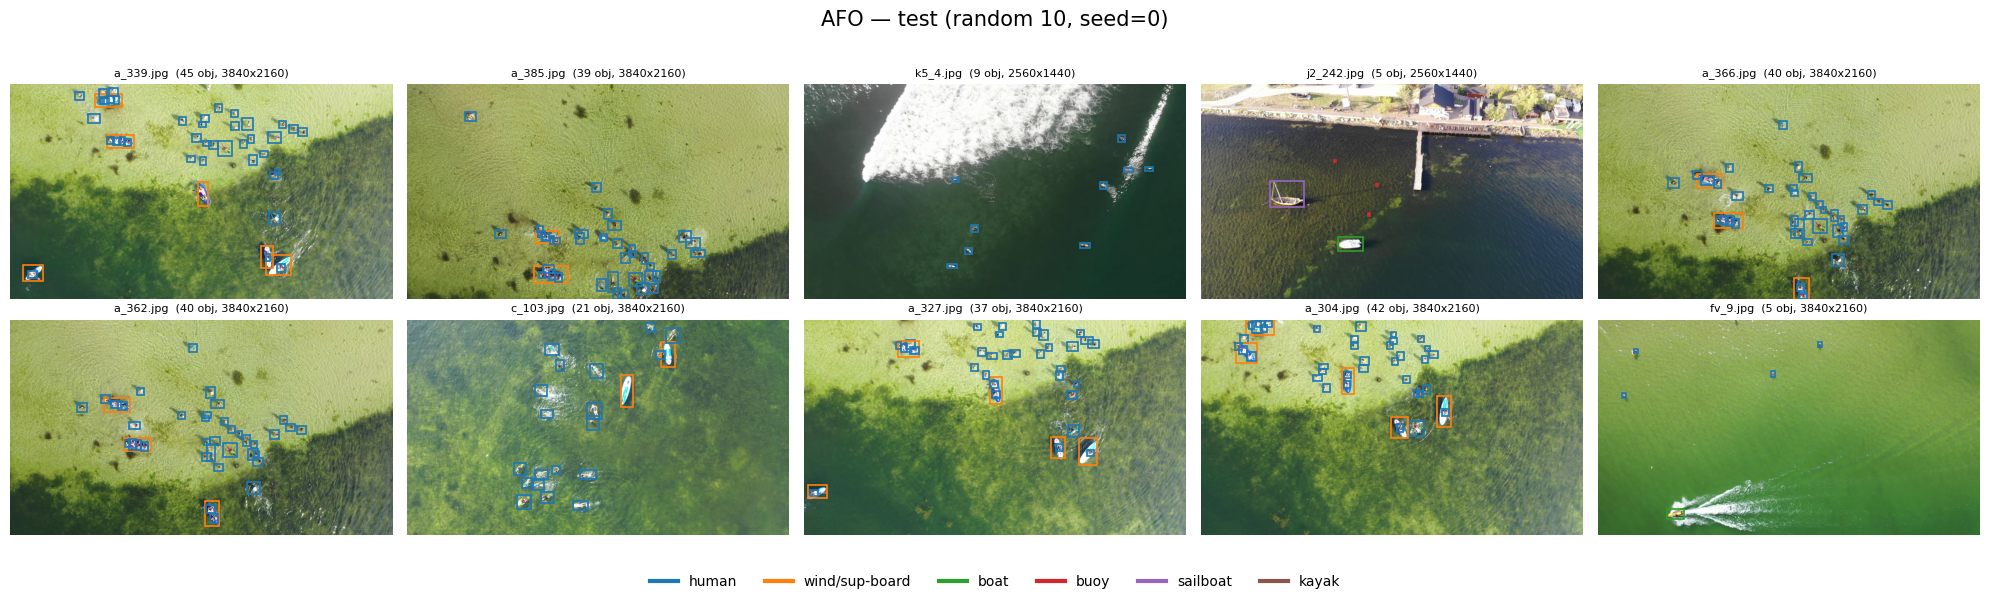

In [2]:
PALETTE = plt.get_cmap('tab10').colors


def draw_split(split, n=10, ncols=5, seed=SEED):
    rng = random.Random(seed)
    recs = rng.sample(ds[split].records, k=min(n, len(ds[split])))
    nrows = math.ceil(len(recs) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3.0 * nrows))
    for ax, rec in zip(np.ravel(axes), recs):
        img = rec.load_image()
        W, H = img.size
        ax.imshow(img)
        for a in rec.annotations:
            x1, y1, x2, y2 = a.to_xyxy(W, H)
            ax.add_patch(
                Rectangle(
                    (x1, y1), x2 - x1, y2 - y1,
                    fill=False, lw=1.2, edgecolor=PALETTE[a.class_id % len(PALETTE)],
                )
            )
        ax.set_title(f'{rec.filename}  ({len(rec.annotations)} obj, {W}x{H})', fontsize=8)
        ax.axis('off')
    for ax in np.ravel(axes)[len(recs):]:
        ax.axis('off')
    handles = [
        plt.Line2D([], [], color=PALETTE[i % len(PALETTE)], lw=3, label=c)
        for i, c in enumerate(LABELS)
    ]
    fig.legend(handles=handles, loc='lower center', ncol=len(LABELS), frameon=False)
    fig.suptitle(f'AFO — {split} (random {len(recs)}, seed={seed})', fontsize=15)
    fig.tight_layout(rect=[0, 0.05, 1, 0.97], h_pad=2.0)
    plt.show()


for s in SPLITS:
    draw_split(s)

## 2. Class histogram

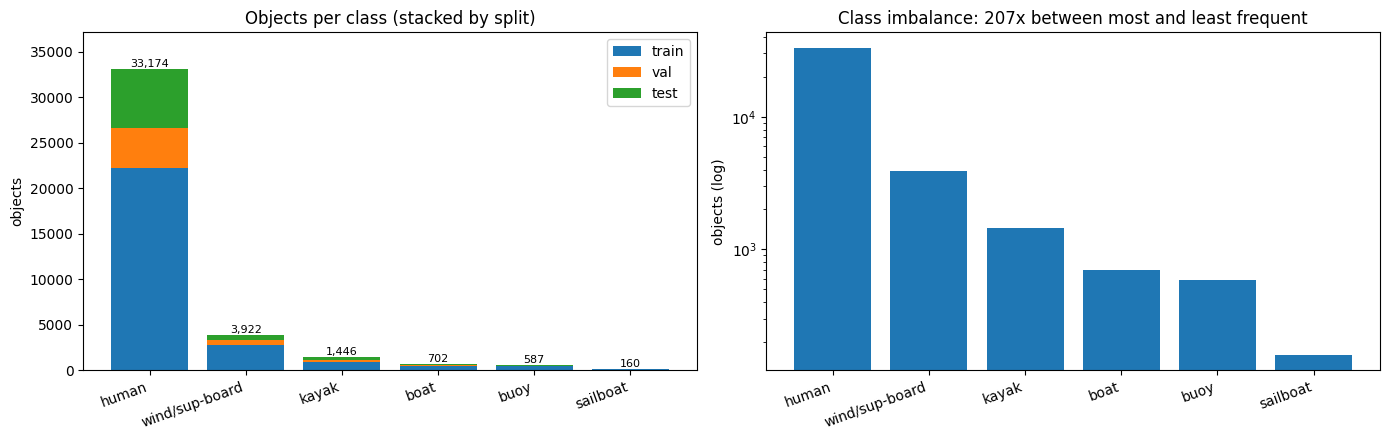

human            33,174  82.95%
wind/sup-board    3,922   9.81%
kayak             1,446   3.62%
boat                702   1.76%
buoy                587   1.47%
sailboat            160   0.40%


In [3]:
hist = {s: ds[s].class_histogram() for s in SPLITS}
totals = {c: sum(hist[s][c] for s in SPLITS) for c in CLASSES}
order = sorted(CLASSES, key=lambda c: -totals[c])
order_lbl = [display_name(c) for c in order]
x = np.arange(len(order))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
bottom = np.zeros(len(order))
for i, s in enumerate(SPLITS):
    vals = np.array([hist[s][c] for c in order], dtype=float)
    axes[0].bar(x, vals, bottom=bottom, label=s, color=PALETTE[i])
    bottom += vals
axes[0].set_xticks(x, order_lbl, rotation=20, ha='right')
axes[0].set_ylabel('objects')
axes[0].set_title('Objects per class (stacked by split)')
axes[0].legend()
for xi, c in zip(x, order):
    axes[0].text(xi, totals[c], f'{totals[c]:,}', ha='center', va='bottom', fontsize=8)
axes[0].margins(y=0.12)

axes[1].bar(x, [totals[c] for c in order], color=PALETTE[0])
axes[1].set_yscale('log')
axes[1].set_xticks(x, order_lbl, rotation=20, ha='right')
axes[1].set_ylabel('objects (log)')
axes[1].set_title(f'Class imbalance: {max(totals.values()) / max(min(totals.values()), 1):.0f}x '
                  'between most and least frequent')
fig.tight_layout()
plt.show()

for c in order:
    print(f'{display_name(c):16s} {totals[c]:6,d}  {100 * totals[c] / sum(totals.values()):5.2f}%')

## 3. Object size — pixels and relative to the image

AFO-specific buckets: tiny `<16²`, small `16²–32²`, medium `32²–96²`, large `>96²` px of box area.

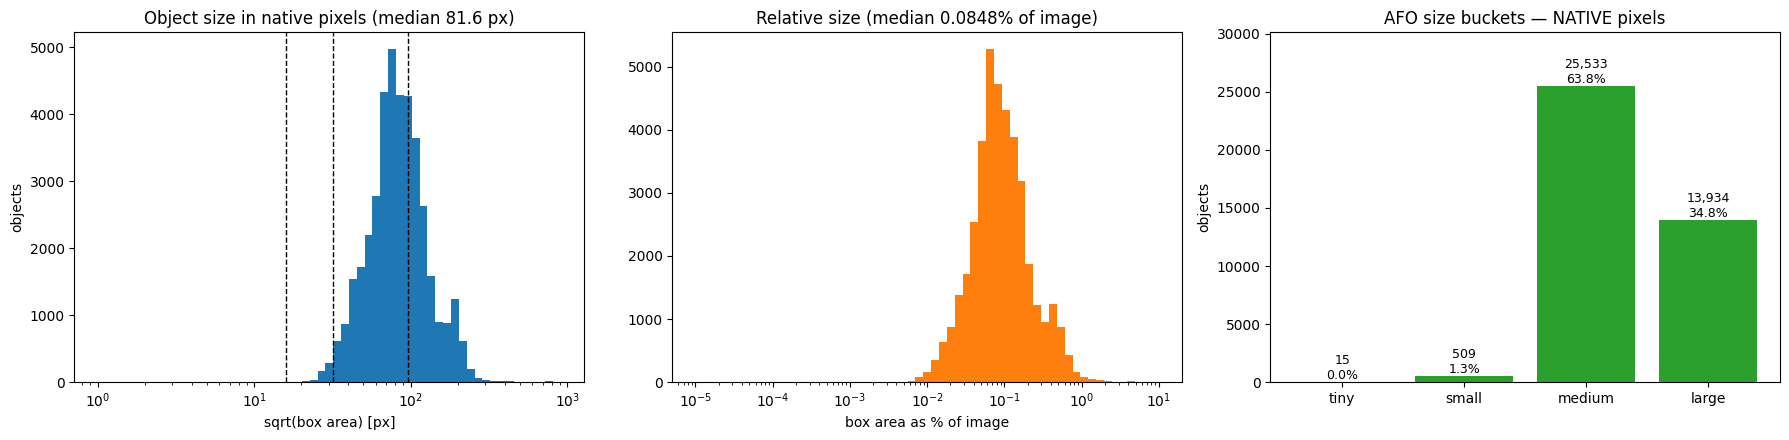

native pixels:
  tiny           15    0.04%
  small         509    1.27%
  medium     25,533   63.85%
  large      13,934   34.84%


In [4]:
BUCKETS = [('tiny', 0, 16), ('small', 16, 32), ('medium', 32, 96), ('large', 96, np.inf)]

sides, rel_area, cls_of, maxdim = [], [], [], []
for s in SPLITS:
    for rec in ds[s].records:
        W, H = rec.size()
        for a in rec.annotations:
            area = (a.w * W) * (a.h * H)
            sides.append(math.sqrt(max(area, 0.0)))
            rel_area.append(a.w * a.h)
            cls_of.append(a.class_id)
            maxdim.append(max(W, H))

sides = np.array(sides)
rel_area = np.array(rel_area)
cls_of = np.array(cls_of)
maxdim = np.array(maxdim, dtype=float)


def bucket_counts(side_arr):
    return [int(((side_arr >= lo) & (side_arr < hi)).sum()) for _, lo, hi in BUCKETS]


fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

axes[0].hist(sides, bins=np.logspace(0, math.log10(max(sides.max(), 10)), 60), color=PALETTE[0])
axes[0].set_xscale('log')
for _, lo, _ in BUCKETS[1:]:
    axes[0].axvline(lo, color='k', ls='--', lw=1)
axes[0].set_xlabel('sqrt(box area) [px]')
axes[0].set_ylabel('objects')
axes[0].set_title(f'Object size in native pixels (median {np.median(sides):.1f} px)')

axes[1].hist(100 * rel_area, bins=np.logspace(-5, 1, 60), color=PALETTE[1])
axes[1].set_xscale('log')
axes[1].set_xlabel('box area as % of image')
axes[1].set_title(f'Relative size (median {100 * np.median(rel_area):.4f}% of image)')

counts = bucket_counts(sides)
axes[2].bar([b[0] for b in BUCKETS], counts, color=PALETTE[2])
for i, v in enumerate(counts):
    axes[2].text(i, v, f'{v:,}\n{100 * v / len(sides):.1f}%', ha='center', va='bottom', fontsize=9)
axes[2].set_ylabel('objects')
axes[2].set_title('AFO size buckets — NATIVE pixels')
axes[2].margins(y=0.18)
fig.tight_layout()
plt.show()

print('native pixels:')
for (name, _, _), v in zip(BUCKETS, counts):
    print(f'  {name:9s} {v:7,d}  {100 * v / len(sides):6.2f}%')

### 3b. The same buckets at the resolution the model actually sees

In native pixels 98.7% of AFO objects are medium or large, and `tiny` holds **15 objects in the whole dataset**. That is an artifact of the 2.5K–4K imagery, not a property of the task. Rescale every box by `imgsz / max(W, H)` — what a detector's letterbox does — and the buckets separate the data properly. This is the view that predicts detection difficulty.

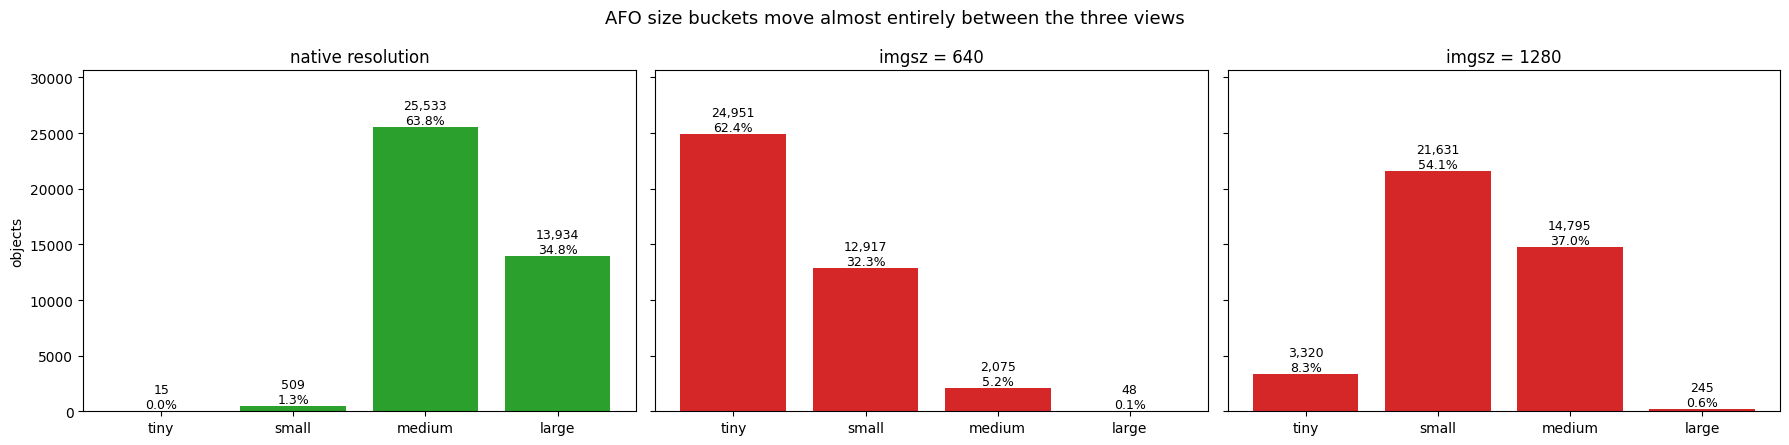

bucket                native          imgsz=640         imgsz=1280
tiny              15 ( 0.04%)    24,951 (62.39%)     3,320 ( 8.30%)
small            509 ( 1.27%)    12,917 (32.30%)    21,631 (54.09%)
medium        25,533 (63.85%)     2,075 ( 5.19%)    14,795 (37.00%)
large         13,934 (34.84%)        48 ( 0.12%)       245 ( 0.61%)


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)
for ax, imgsz in zip(axes, (None, 640, 1280)):
    scaled = sides if imgsz is None else sides * (imgsz / maxdim)
    c = bucket_counts(scaled)
    ax.bar([b[0] for b in BUCKETS], c, color=PALETTE[2 if imgsz is None else 3])
    for i, v in enumerate(c):
        ax.text(i, v, f'{v:,}\n{100 * v / len(scaled):.1f}%', ha='center', va='bottom', fontsize=9)
    ax.set_title('native resolution' if imgsz is None else f'imgsz = {imgsz}')
    ax.margins(y=0.2)
axes[0].set_ylabel('objects')
fig.suptitle('AFO size buckets move almost entirely between the three views', fontsize=13)
fig.tight_layout()
plt.show()

print(f'{"bucket":9s} {"native":>18s} {"imgsz=640":>18s} {"imgsz=1280":>18s}')
cols = [bucket_counts(sides if z is None else sides * (z / maxdim)) for z in (None, 640, 1280)]
for i, (name, _, _) in enumerate(BUCKETS):
    cells = ''.join(f'{c[i]:10,d} ({100 * c[i] / len(sides):5.2f}%)' for c in cols)
    print(f'{name:9s} {cells}')

## 4. Size per class

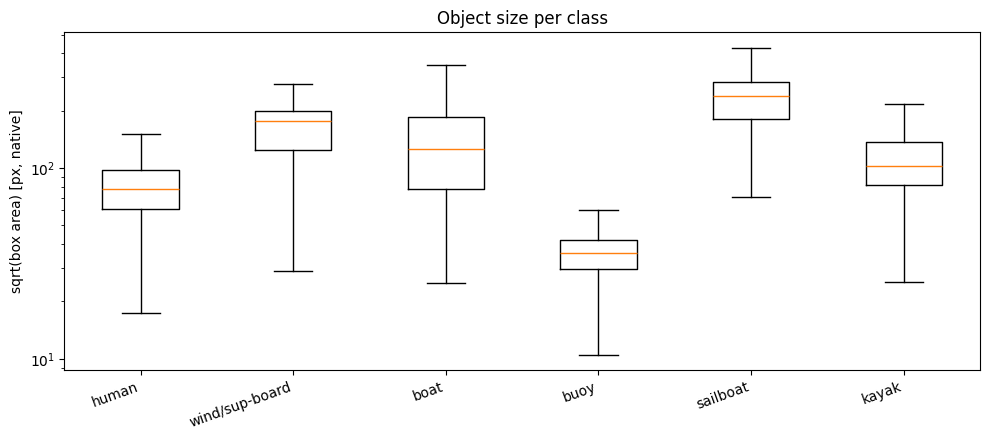

human            n=33,174  median   77.2 px  p95   130.1 px
wind/sup-board   n= 3,922  median  175.4 px  p95   225.2 px
boat             n=   702  median  125.5 px  p95   331.9 px
buoy             n=   587  median   35.9 px  p95    50.4 px
sailboat         n=   160  median  238.8 px  p95   727.8 px
kayak            n= 1,446  median  102.0 px  p95   180.3 px


In [6]:
fig, ax = plt.subplots(figsize=(10, 4.5))
data = [sides[cls_of == i] for i in range(len(CLASSES))]
ax.boxplot([d if len(d) else [0] for d in data], tick_labels=LABELS, showfliers=False)
ax.set_yscale('log')
ax.set_ylabel('sqrt(box area) [px, native]')
ax.set_title('Object size per class')
plt.xticks(rotation=20, ha='right')
fig.tight_layout()
plt.show()

for i, c in enumerate(LABELS):
    d = data[i]
    if len(d):
        print(f'{c:16s} n={len(d):6,d}  median {np.median(d):6.1f} px  p95 {np.percentile(d, 95):7.1f} px')